In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [4]:
df=pd.read_csv("data/raw/incident_event_log.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/incident_event_log.csv'

In [5]:
import os

In [6]:
print(os.getcwd())

C:\AI_Projects\enterprise-ai-incident-platform\notebooks


In [7]:
df = pd.read_csv("../data/raw/incident_event_log.csv")

In [8]:
df.head()

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


In [9]:
print(df.shape)

(141712, 36)


In [10]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   number                   141712 non-null  str  
 1   incident_state           141712 non-null  str  
 2   active                   141712 non-null  bool 
 3   reassignment_count       141712 non-null  int64
 4   reopen_count             141712 non-null  int64
 5   sys_mod_count            141712 non-null  int64
 6   made_sla                 141712 non-null  bool 
 7   caller_id                141712 non-null  str  
 8   opened_by                141712 non-null  str  
 9   opened_at                141712 non-null  str  
 10  sys_created_by           141712 non-null  str  
 11  sys_created_at           141712 non-null  str  
 12  sys_updated_by           141712 non-null  str  
 13  sys_updated_at           141712 non-null  str  
 14  contact_type             141712 non-null  str  

In [11]:
print(df.isnull().sum())

number                     0
incident_state             0
active                     0
reassignment_count         0
reopen_count               0
sys_mod_count              0
made_sla                   0
caller_id                  0
opened_by                  0
opened_at                  0
sys_created_by             0
sys_created_at             0
sys_updated_by             0
sys_updated_at             0
contact_type               0
location                   0
category                   0
subcategory                0
u_symptom                  0
cmdb_ci                    0
impact                     0
urgency                    0
priority                   0
assignment_group           0
assigned_to                0
knowledge                  0
u_priority_confirmation    0
notify                     0
problem_id                 0
rfc                        0
vendor                     0
caused_by                  0
closed_code                0
resolved_by                0
resolved_at   

In [12]:
print(df.describe(include="all"))

            number incident_state  active  reassignment_count   reopen_count  \
count       141712         141712  141712       141712.000000  141712.000000   
unique       24918              9       2                 NaN            NaN   
top     INC0019396         Active    True                 NaN            NaN   
freq            58          38716  116726                 NaN            NaN   
mean           NaN            NaN     NaN            1.104197       0.021918   
std            NaN            NaN     NaN            1.734673       0.207302   
min            NaN            NaN     NaN            0.000000       0.000000   
25%            NaN            NaN     NaN            0.000000       0.000000   
50%            NaN            NaN     NaN            1.000000       0.000000   
75%            NaN            NaN     NaN            1.000000       0.000000   
max            NaN            NaN     NaN           27.000000       8.000000   

        sys_mod_count made_sla    calle

In [13]:
df["number"].value_counts().head(10)

number
INC0019396    58
INC0044260    56
INC0005927    46
INC0020718    45
INC0011206    44
INC0007349    43
INC0025734    43
INC0012815    40
INC0003419    38
INC0020849    38
Name: count, dtype: int64

In [14]:
print("Total records: ",len(df))

Total records:  141712


In [15]:
print("Unique Incidents: ",df["number"].nunique())

Unique Incidents:  24918


In [16]:
print("Diplicate Incident records: ",df.duplicated("number").sum())

Diplicate Incident records:  116794


In [17]:
incident_counts=df["number"].value_counts()

In [18]:
print(incident_counts)

number
INC0019396    58
INC0044260    56
INC0005927    46
INC0020718    45
INC0011206    44
              ..
INC0119983     2
INC0119987     2
INC0120268     2
INC0120303     2
INC0120319     2
Name: count, Length: 24918, dtype: int64


In [19]:
print(incident_counts.describe())

count    24918.000000
mean         5.687134
std          3.677845
min          2.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         58.000000
Name: count, dtype: float64


In [23]:
print(incident_counts.head(100))

number
INC0019396    58
INC0044260    56
INC0005927    46
INC0020718    45
INC0011206    44
              ..
INC0004459    23
INC0006959    23
INC0009953    23
INC0010293    23
INC0010676    23
Name: count, Length: 100, dtype: int64


In [24]:
sample_id=incident_counts.index[0]

In [25]:
sample=df[df["number"]==sample_id]

In [30]:
display(sample.T)

,81418,81419,81420,81421,81422,81423,81424,81425,81426,81427,...,81466,81467,81468,81469,81470,81471,81472,81473,81474,81475
number,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,...,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396,INC0019396
incident_state,New,New,Resolved,Active,Active,Active,Active,Active,Active,Active,...,Resolved,Active,Active,Active,Active,Resolved,Active,Active,Resolved,Closed
active,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,False
reassignment_count,0,0,0,0,0,0,0,0,0,1,...,10,10,10,10,10,10,10,10,10,10
reopen_count,0,0,0,1,1,1,1,1,1,1,...,6,7,7,7,7,7,8,8,8,8
sys_mod_count,0,1,6,7,9,10,11,12,16,18,...,58,59,60,61,62,63,64,66,67,68
made_sla,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,False
caller_id,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,...,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580,Caller 1580
opened_by,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,...,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305,Opened by 305
opened_at,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,...,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42,14/4/2016 20:42


In [28]:
print(df["incident_state"].value_counts(dropna=False))

incident_state
Active                38716
New                   36407
Resolved              25751
Closed                24985
Awaiting User Info    14642
Awaiting Vendor         707
Awaiting Problem        461
Awaiting Evidence        38
-100                      5
Name: count, dtype: int64


In [29]:
print(df["priority"].value_counts(dropna=False))

priority
3 - Moderate    132452
4 - Low           4030
2 - High          2972
1 - Critical      2258
Name: count, dtype: int64


In [34]:
priority_changes=df.groupby("number")["priority"].nunique()

In [35]:
print(priority_changes.value_counts())

priority
1    24535
2      351
3       32
Name: count, dtype: int64


In [36]:
state_changes=df.groupby("number")["incident_state"].nunique()

In [37]:
print(state_changes.value_counts())

incident_state
3    11804
4     8361
5     2837
2     1827
6       85
7        4
Name: count, dtype: int64


In [38]:
print("Total Incidents: ",df["number"].nunique())

Total Incidents:  24918


In [39]:
print("Total rows: ",len(df))

Total rows:  141712


In [40]:
display(
    sample[["number", "incident_state", "priority", "reopen_count"]]
)

,number,incident_state,priority,reopen_count
81418,INC0019396,New,3 - Moderate,0
81419,INC0019396,New,3 - Moderate,0
81420,INC0019396,Resolved,3 - Moderate,0
81421,INC0019396,Active,3 - Moderate,1
81422,INC0019396,Active,3 - Moderate,1
81423,INC0019396,Active,3 - Moderate,1
81424,INC0019396,Active,3 - Moderate,1
81425,INC0019396,Active,3 - Moderate,1
81426,INC0019396,Active,3 - Moderate,1
81427,INC0019396,Active,3 - Moderate,1


In [41]:
data = {
    "number": ["INC001", "INC001", "INC001",
               "INC002", "INC002", "INC003"],
    "incident_state": ["New", "New", "Active",
                       "New", "Resolved", "New"]
}

df_test = pd.DataFrame(data)

In [44]:
print(df_test.groupby("number")["incident_state"].nunique())

number
INC001    2
INC002    2
INC003    1
Name: incident_state, dtype: int64


In [45]:
print(df_test.groupby("number")["incident_state"].nunique().value_counts())

incident_state
2    2
1    1
Name: count, dtype: int64


In [46]:
priority_changes=df.groupby("number")["priority"].nunique()

print(priority_changes.head(10))

number
INC0000045    1
INC0000047    1
INC0000057    1
INC0000060    1
INC0000062    2
INC0000063    1
INC0000064    1
INC0000065    1
INC0000066    1
INC0000067    1
Name: priority, dtype: int64


In [47]:
print(priority_changes.value_counts())

priority
1    24535
2      351
3       32
Name: count, dtype: int64


In [48]:
changed_incidents=priority_changes[priority_changes>1]

print(changed_incidents.head())

number
INC0000062    2
INC0000104    2
INC0000161    3
INC0000171    2
INC0000341    2
Name: priority, dtype: int64


In [51]:
sample_id=changed_incidents.index[0]

history=df[df["number"]==sample_id]

display(
    history[[
        "number","priority","incident_state","sys_updated_at","reopen_count"
    ]]
)

,number,priority,incident_state,sys_updated_at,reopen_count
24,INC0000062,3 - Moderate,New,29/2/2016 07:26,0
25,INC0000062,2 - High,New,29/2/2016 07:29,0
26,INC0000062,2 - High,New,29/2/2016 07:34,0
27,INC0000062,2 - High,New,29/2/2016 11:23,0
28,INC0000062,2 - High,New,29/2/2016 11:28,0
29,INC0000062,2 - High,New,29/2/2016 15:51,0
30,INC0000062,2 - High,Resolved,29/2/2016 15:51,0
31,INC0000062,2 - High,Closed,5/3/2016 16:00,0


In [54]:
changed_history=df[df["number"].isin(changed_incidents.index)]

priority_timeline=changed_history[["number","priority","sys_updated_at"]]

display(priority_timeline.head(20))

,number,priority,sys_updated_at
24,INC0000062,3 - Moderate,29/2/2016 07:26
25,INC0000062,2 - High,29/2/2016 07:29
26,INC0000062,2 - High,29/2/2016 07:34
27,INC0000062,2 - High,29/2/2016 11:23
28,INC0000062,2 - High,29/2/2016 11:28
29,INC0000062,2 - High,29/2/2016 15:51
30,INC0000062,2 - High,29/2/2016 15:51
31,INC0000062,2 - High,5/3/2016 16:00
224,INC0000104,3 - Moderate,29/2/2016 09:17
225,INC0000104,2 - High,29/2/2016 09:18


In [55]:
changed_history=df[df["number"].isin(changed_incidents.index)]

priority_timeline=changed_history[["number","priority","opened_at","sys_updated_at"]]

display(priority_timeline.head(20))

,number,priority,opened_at,sys_updated_at
24,INC0000062,3 - Moderate,29/2/2016 06:58,29/2/2016 07:26
25,INC0000062,2 - High,29/2/2016 06:58,29/2/2016 07:29
26,INC0000062,2 - High,29/2/2016 06:58,29/2/2016 07:34
27,INC0000062,2 - High,29/2/2016 06:58,29/2/2016 11:23
28,INC0000062,2 - High,29/2/2016 06:58,29/2/2016 11:28
29,INC0000062,2 - High,29/2/2016 06:58,29/2/2016 15:51
30,INC0000062,2 - High,29/2/2016 06:58,29/2/2016 15:51
31,INC0000062,2 - High,29/2/2016 06:58,5/3/2016 16:00
224,INC0000104,3 - Moderate,29/2/2016 09:08,29/2/2016 09:17
225,INC0000104,2 - High,29/2/2016 09:08,29/2/2016 09:18


In [56]:
print(df[["opened_at","sys_updated_at"]].dtypes)

opened_at         str
sys_updated_at    str
dtype: object


In [57]:
df["opened_at"]=pd.to_datetime(df["opened_at"],dayfirst=True)

In [58]:
df["sys_updated_at"]=pd.to_datetime(df["sys_updated_at"],dayfirst=True)

In [60]:
print(df.head().dtypes)

number                                str
incident_state                        str
active                               bool
reassignment_count                  int64
reopen_count                        int64
sys_mod_count                       int64
made_sla                             bool
caller_id                             str
opened_by                             str
opened_at                  datetime64[us]
sys_created_by                        str
sys_created_at                        str
sys_updated_by                        str
sys_updated_at             datetime64[us]
contact_type                          str
location                              str
category                              str
subcategory                           str
u_symptom                             str
cmdb_ci                               str
impact                                str
urgency                               str
priority                              str
assignment_group                  

In [78]:
first_records=(
    df.sort_values("sys_updated_at")
    .groupby("number")
    .first()
    .reset_index()
)

In [79]:
print(first_records.shape)

(24918, 36)


In [80]:
display(first_records[["number","priority","opened_at","sys_updated_at"]].head(10))
# print(first_records[["number"]].head())

,number,priority,opened_at,sys_updated_at
0,INC0000045,3 - Moderate,2016-02-29 01:16:00,2016-02-29 01:23:00
1,INC0000047,3 - Moderate,2016-02-29 04:40:00,2016-02-29 04:57:00
2,INC0000057,3 - Moderate,2016-02-29 06:10:00,2016-02-29 06:26:00
3,INC0000060,3 - Moderate,2016-02-29 06:38:00,2016-02-29 06:42:00
4,INC0000062,3 - Moderate,2016-02-29 06:58:00,2016-02-29 07:26:00
5,INC0000063,3 - Moderate,2016-02-29 07:08:00,2016-02-29 07:17:00
6,INC0000064,3 - Moderate,2016-02-29 07:10:00,2016-02-29 07:14:00
7,INC0000065,3 - Moderate,2016-02-29 07:38:00,2016-02-29 07:46:00
8,INC0000066,3 - Moderate,2016-02-29 08:03:00,2016-02-29 08:18:00
9,INC0000067,3 - Moderate,2016-02-29 08:03:00,2016-02-29 08:05:00


In [82]:
first_records=(
    df.sort_values("sys_updated_at")
      .drop_duplicates(subset="number",keep="first")
      .reset_index(drop=True)
)

In [83]:
display(first_records[["number","priority","opened_at","sys_updated_at"]].head(10))

,number,priority,opened_at,sys_updated_at
0,INC0000045,3 - Moderate,2016-02-29 01:16:00,2016-02-29 01:23:00
1,INC0000047,3 - Moderate,2016-02-29 04:40:00,2016-02-29 04:57:00
2,INC0000057,3 - Moderate,2016-02-29 06:10:00,2016-02-29 06:26:00
3,INC0000060,3 - Moderate,2016-02-29 06:38:00,2016-02-29 06:42:00
4,INC0000064,3 - Moderate,2016-02-29 07:10:00,2016-02-29 07:14:00
5,INC0000131,3 - Moderate,2016-02-29 09:41:00,2016-02-29 07:14:00
6,INC0000063,3 - Moderate,2016-02-29 07:08:00,2016-02-29 07:17:00
7,INC0000062,3 - Moderate,2016-02-29 06:58:00,2016-02-29 07:26:00
8,INC0000130,3 - Moderate,2016-02-29 09:41:00,2016-02-29 07:27:00
9,INC0000065,3 - Moderate,2016-02-29 07:38:00,2016-02-29 07:46:00


In [84]:
print(first_records.shape)

(24918, 36)


In [85]:
print(df.shape)

(141712, 36)


In [86]:
print("Total rows: ",len(first_records))

Total rows:  24918


In [87]:
print("Unique Incidents: ", first_records["number"].nunique())

Unique Incidents:  24918


In [88]:
print("Duplicate Incidents: ",first_records["number"].duplicated().sum())

Duplicate Incidents:  0


In [89]:
print(first_records["priority"].value_counts())

priority
3 - Moderate    23674
4 - Low           741
2 - High          317
1 - Critical      186
Name: count, dtype: int64


In [90]:
print("Priority Percentages: ")

Priority Percentages: 


In [91]:
print("Priority Percentages: ")

print(
    first_records["priority"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Priority Percentages: 
priority
3 - Moderate    95.01
4 - Low          2.97
2 - High         1.27
1 - Critical     0.75
Name: proportion, dtype: float64


In [92]:
print(first_records.columns.tolist())

['number', 'incident_state', 'active', 'reassignment_count', 'reopen_count', 'sys_mod_count', 'made_sla', 'caller_id', 'opened_by', 'opened_at', 'sys_created_by', 'sys_created_at', 'sys_updated_by', 'sys_updated_at', 'contact_type', 'location', 'category', 'subcategory', 'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority', 'assignment_group', 'assigned_to', 'knowledge', 'u_priority_confirmation', 'notify', 'problem_id', 'rfc', 'vendor', 'caused_by', 'closed_code', 'resolved_by', 'resolved_at', 'closed_at']


In [93]:
print("Priority:")
print(first_records["priority"].value_counts())

print("\n Impact: ")
print(first_records["impact"].value_counts())

print("\n Urgency:")
print(first_records["urgency"].value_counts())

Priority:
priority
3 - Moderate    23674
4 - Low           741
2 - High          317
1 - Critical      186
Name: count, dtype: int64

 Impact: 
impact
2 - Medium    23904
3 - Low         726
1 - High        288
Name: count, dtype: int64

 Urgency:
urgency
2 - Medium    23842
3 - Low         675
1 - High        401
Name: count, dtype: int64


In [94]:
pd.crosstab([first_records["impact"],first_records["urgency"]],
            first_records["priority"])

priority               1 - Critical  2 - High  3 - Moderate  4 - Low
impact     urgency                                                  
1 - High   1 - High             186         0             0        0
           2 - Medium             0       102             0        0
2 - Medium 1 - High               0       215             0        0
           2 - Medium             0         0         23674        0
           3 - Low                0         0             0       15
3 - Low    2 - Medium             0         0             0       66
           3 - Low                0         0             0      660

In [95]:
print(first_records["u_priority_confirmation"].value_counts())

u_priority_confirmation
False    24821
True        97
Name: count, dtype: int64


In [96]:
pd.crosstab(first_records["u_priority_confirmation"],first_records["priority"])

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
u_priority_confirmation,,,,
False,172,316,23600,733
True,14,1,74,8


In [98]:
first_records["time_difference"]=(first_records["sys_updated_at"]-first_records["opened_at"])

In [99]:
display(first_records["time_difference"].describe())

count                     24918
mean     0 days 00:05:08.738261
std      0 days 00:13:50.621697
min           -1 days +21:33:00
25%             0 days 00:00:00
50%             0 days 00:01:00
75%             0 days 00:06:00
max             0 days 19:06:00
Name: time_difference, dtype: object

In [101]:
negative_records=first_records[first_records["time_difference"]<pd.Timedelta(0)]

In [102]:
display(
    negative_records[
        ["number","opened_at","sys_updated_at","time_difference","priority"]
    ].head(10)
)

,number,opened_at,sys_updated_at,time_difference,priority
5,INC0000131,2016-02-29 09:41:00,2016-02-29 07:14:00,-1 days +21:33:00,3 - Moderate
8,INC0000130,2016-02-29 09:41:00,2016-02-29 07:27:00,-1 days +21:46:00,3 - Moderate
10,INC0000134,2016-02-29 09:44:00,2016-02-29 07:55:00,-1 days +22:11:00,4 - Low
25,INC0000164,2016-02-29 10:18:00,2016-02-29 08:53:00,-1 days +22:35:00,3 - Moderate
46,INC0000135,2016-02-29 09:45:00,2016-02-29 09:27:00,-1 days +23:42:00,3 - Moderate


In [103]:
clean_records=first_records[first_records["time_difference"]>=pd.Timedelta(0)].copy()

In [104]:
print("Before: ",len(first_records))

print("After: ",len(clean_records))

print("Removed: ",len(first_records)-len(clean_records))

Before:  24918
After:  24913
Removed:  5


In [106]:
missing_values=clean_records.isnull().sum()



In [107]:
missing_values=missing_values[missing_values>0].sort_values(ascending=False)

display(missing_values)

Series([], dtype: int64)

In [108]:
empty_counts=(clean_records=="").sum()

display(empty_counts[empty_counts>0])

Series([], dtype: int64)

In [109]:
display(clean_records["priority"].value_counts())

priority
3 - Moderate    23670
4 - Low           740
2 - High          317
1 - Critical      186
Name: count, dtype: int64

In [110]:
display(clean_records["priority"].value_counts(normalize=True)*100)

priority
3 - Moderate    95.010637
4 - Low          2.970337
2 - High         1.272428
1 - Critical     0.746598
Name: proportion, dtype: float64

In [111]:
display(clean_records.nunique().sort_values())

reopen_count                   1
active                         2
made_sla                       2
u_priority_confirmation        2
notify                         2
knowledge                      2
urgency                        3
reassignment_count             3
impact                         3
vendor                         3
caused_by                      3
priority                       4
sys_mod_count                  4
contact_type                   5
incident_state                 8
closed_code                   18
cmdb_ci                       46
category                      58
assignment_group              70
rfc                           97
time_difference              138
problem_id                   163
sys_created_by               186
sys_updated_by               190
assigned_to                  206
opened_by                    208
resolved_by                  217
location                     220
subcategory                  247
u_symptom                    501
closed_at 

In [113]:
constant_columns=clean_records.nunique()

constant_columns=constant_columns[constant_columns==1]

display(constant_columns)

reopen_count    1
dtype: int64

In [114]:
clean_records=clean_records.drop(columns=["reopen_count"])

In [115]:
display(clean_records.columns.tolist())

['number',
 'incident_state',
 'active',
 'reassignment_count',
 'sys_mod_count',
 'made_sla',
 'caller_id',
 'opened_by',
 'opened_at',
 'sys_created_by',
 'sys_created_at',
 'sys_updated_by',
 'sys_updated_at',
 'contact_type',
 'location',
 'category',
 'subcategory',
 'u_symptom',
 'cmdb_ci',
 'impact',
 'urgency',
 'priority',
 'assignment_group',
 'assigned_to',
 'knowledge',
 'u_priority_confirmation',
 'notify',
 'problem_id',
 'rfc',
 'vendor',
 'caused_by',
 'closed_code',
 'resolved_by',
 'resolved_at',
 'closed_at',
 'time_difference']

In [116]:
clean_records["creation_difference"]=(clean_records["opened_at"]-clean_records["sys_created_at"])

display(clean_records["creation_difference"].describe())

C:\Users\mukhesh\AppData\Local\Temp\ipykernel_23728\53583988.py:1: PerformanceWarning: Adding/subtracting object-dtype array to DatetimeArray not vectorized.
  clean_records["creation_difference"]=(clean_records["opened_at"]-clean_records["sys_created_at"])


TypeError: unsupported operand type(s) for -: 'Timestamp' and 'str'

In [117]:
clean_records["sys_created_at"]=pd.to_datetime(clean_records["sys_created_at"],dayfirst=True)

ValueError: time data "?" doesn't match format "%d/%m/%Y %H:%M". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [119]:
invalid_dates=clean_records[
    pd.to_datetime(
        clean_records["sys_created_at"],
        dayfirst=True,
        errors="coerce"
    ).isna()
]

display(invalid_dates[["number","sys_created_at"]])

,number,sys_created_at
2,INC0000057,?
14,INC0000074,?
15,INC0000077,?
18,INC0000079,?
19,INC0000080,?
...,...,...
24913,INC0120304,?
24914,INC0120319,?
24915,INC0120495,?
24916,INC0120835,?


In [120]:
display(clean_records["opened_at"].isna().sum())

np.int64(0)

In [121]:
clean_records["opened_hour"]=clean_records["opened_at"].dt.hour

display(clean_records["opened_hour"].value_counts().sort_index())

opened_hour
0      269
1      222
2      149
3      123
4      128
5      132
6      320
7      573
8     2547
9     3010
10    2892
11    2469
12    1342
13    1645
14    2255
15    2131
16    1867
17    1075
18     466
19     296
20     226
21     359
22     245
23     172
Name: count, dtype: int64

In [122]:
pd.crosstab(
    clean_records["opened_hour"],
    clean_records["priority"]
)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
opened_hour,,,,
0,9,10,249,1
1,10,9,201,2
2,3,3,140,3
3,1,3,115,4
4,1,4,122,1
5,4,4,124,0
6,0,8,300,12
7,6,4,525,38
8,13,23,2408,103


In [125]:
hour_priority_percentage=pd.crosstab(
    clean_records["opened_hour"],
    clean_records["priority"],
    normalize="index"
)*100

display(hour_priority_percentage.round(2))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
opened_hour,,,,
0,3.35,3.72,92.57,0.37
1,4.50,4.05,90.54,0.90
2,2.01,2.01,93.96,2.01
3,0.81,2.44,93.50,3.25
4,0.78,3.12,95.31,0.78
5,3.03,3.03,93.94,0.00
6,0.00,2.50,93.75,3.75
7,1.05,0.70,91.62,6.63
8,0.51,0.90,94.54,4.04


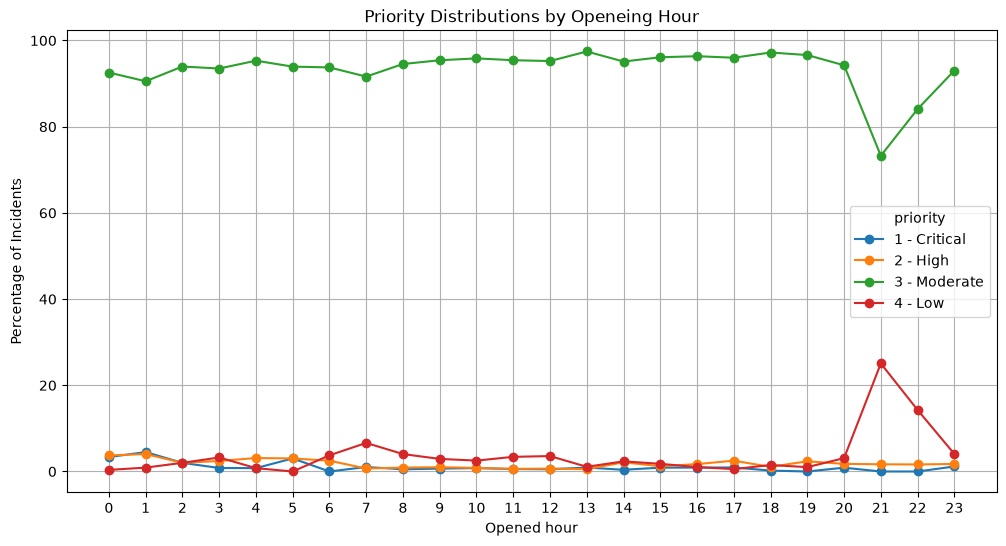

In [130]:
hour_priority_percentage.plot(
    kind="line",
    figsize=(12,6),
    marker='o'
)
plt.xlabel("Opened hour")
plt.ylabel("Percentage of Incidents")
plt.title("Priority Distributions by Openeing Hour")
plt.xticks(range(24))
plt.grid(True)
plt.show()

In [131]:
pd.crosstab(
    clean_records["contact_type"],
    clean_records["priority"],
    normalize="index"
).mul(100).round(2)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
contact_type,,,,
Direct opening,0.00,0.00,100.00,0.00
Email,0.00,1.64,98.36,0.00
IVR,0.00,0.00,0.00,100.00
Phone,0.75,1.28,95.01,2.96
Self service,1.24,0.00,98.76,0.00


In [132]:
display(clean_records["contact_type"].value_counts())

contact_type
Phone             24679
Self service        161
Email                61
IVR                   9
Direct opening        3
Name: count, dtype: int64

In [133]:
pd.crosstab(
    clean_records["category"],
    clean_records["priority"],
    normalize="index"
).mul(100).round(2)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
category,,,,
?,0.00,2.56,87.18,10.26
Category 10,0.00,0.00,100.00,0.00
Category 12,0.00,0.00,100.00,0.00
Category 13,0.84,1.68,94.12,3.36
Category 14,0.00,0.00,100.00,0.00
Category 15,0.00,0.00,100.00,0.00
Category 16,0.00,0.00,100.00,0.00
Category 17,5.56,13.89,76.39,4.17
Category 19,4.09,3.18,91.82,0.91


In [134]:
display(clean_records["category"].value_counts())

category
Category 42    3627
Category 26    3268
Category 53    2654
Category 46    2245
Category 32    1494
Category 9     1141
Category 37    1135
Category 23    1072
Category 20    1066
Category 57     916
Category 61     804
Category 40     686
Category 24     638
Category 45     624
Category 51     545
Category 28     522
Category 35     512
Category 34     498
Category 44     331
Category 19     220
Category 43     172
Category 13     119
Category 55      99
Category 17      72
Category 8       52
Category 22      47
?                39
Category 38      37
Category 41      36
Category 56      35
Category 7       31
Category 54      29
Category 50      23
Category 31      18
Category 33      14
Category 63      11
Category 5       10
Category 21       8
Category 47       6
Category 4        6
Category 29       6
Category 59       6
Category 30       5
Category 25       5
Category 2        5
Category 52       5
Category 62       4
Category 10       3
Category 16       2
Category 6 

In [135]:
display(clean_records["subcategory"].value_counts().head(20))

subcategory
Subcategory 174    6645
Subcategory 223    3736
Subcategory 175    1850
Subcategory 164    1241
Subcategory 9       876
Subcategory 135     573
Subcategory 275     563
Subcategory 170     493
Subcategory 36      442
Subcategory 28      424
Subcategory 43      398
Subcategory 125     387
Subcategory 103     310
Subcategory 123     265
Subcategory 3       254
Subcategory 303     248
Subcategory 150     246
Subcategory 75      240
Subcategory 114     214
Subcategory 29      164
Name: count, dtype: int64

In [136]:
subcategory_priority=pd.crosstab(
    clean_records["subcategory"],
    clean_records["priority"],
    normalize="index"
)*100

display(subcategory_priority.round(2).head(20))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
subcategory,,,,
?,0.00,1.45,92.75,5.80
Subcategory 10,0.00,0.00,47.06,52.94
Subcategory 100,0.00,0.00,100.00,0.00
Subcategory 101,0.00,8.33,91.67,0.00
Subcategory 102,0.00,0.00,100.00,0.00
Subcategory 103,0.32,0.32,98.06,1.29
Subcategory 104,0.00,0.00,100.00,0.00
Subcategory 105,0.00,0.00,91.49,8.51
Subcategory 106,0.00,0.00,91.18,8.82


In [137]:
display(clean_records["subcategory"].value_counts().head(20))

subcategory
Subcategory 174    6645
Subcategory 223    3736
Subcategory 175    1850
Subcategory 164    1241
Subcategory 9       876
Subcategory 135     573
Subcategory 275     563
Subcategory 170     493
Subcategory 36      442
Subcategory 28      424
Subcategory 43      398
Subcategory 125     387
Subcategory 103     310
Subcategory 123     265
Subcategory 3       254
Subcategory 303     248
Subcategory 150     246
Subcategory 75      240
Subcategory 114     214
Subcategory 29      164
Name: count, dtype: int64

In [138]:
top_subcategories=clean_records["subcategory"].value_counts().head(20).index

display(subcategory_priority.loc[top_subcategories].round(2))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
subcategory,,,,
Subcategory 174,0.51,1.31,94.96,3.22
Subcategory 223,0.56,0.54,95.74,3.16
Subcategory 175,0.43,0.65,97.03,1.89
Subcategory 164,0.40,0.56,94.52,4.51
Subcategory 9,0.00,0.23,95.89,3.88
Subcategory 135,1.05,0.70,95.46,2.79
Subcategory 275,0.00,0.18,98.93,0.89
Subcategory 170,3.25,3.65,90.67,2.43
Subcategory 36,0.45,0.45,98.19,0.90


In [140]:
subcategory_category=(
    clean_records.groupby("subcategory")["category"].nunique()
)

display(subcategory_category.value_counts())

category
1     200
2      39
3       5
7       1
30      1
19      1
Name: count, dtype: int64

In [145]:
display(clean_records.groupby("category").nunique())

,number,incident_state,active,reassignment_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,...,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at,time_difference,opened_hour
category,,,,,,,,,,,,,,,,,,,,,
?,39,2,1,1,1,1,32,28,38,8,...,2,2,1,1,10,25,38,31,8,13
Category 10,3,1,1,1,1,1,3,3,3,3,...,1,1,1,1,1,3,3,3,3,3
Category 12,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Category 13,119,4,1,2,2,1,106,21,119,20,...,1,1,1,1,10,32,115,100,30,16
Category 14,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Category 15,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Category 16,2,1,1,1,1,1,2,2,2,2,...,1,1,1,1,1,2,2,2,1,1
Category 17,72,3,1,1,1,1,64,28,72,18,...,3,1,1,1,7,28,72,64,14,12
Category 19,220,3,1,2,3,1,181,42,220,33,...,5,2,1,1,10,61,214,162,30,18


In [147]:
display(subcategory_category[subcategory_category>1].sort_values(ascending=False))

subcategory
Subcategory 174    30
Subcategory 177    19
Subcategory 164     7
Subcategory 270     3
Subcategory 223     3
Subcategory 158     3
?                   3
Subcategory 305     3
Subcategory 115     2
Subcategory 118     2
Subcategory 11      2
Subcategory 102     2
Subcategory 107     2
Subcategory 10      2
Subcategory 101     2
Subcategory 150     2
Subcategory 157     2
Subcategory 135     2
Subcategory 146     2
Subcategory 120     2
Subcategory 17      2
Subcategory 170     2
Subcategory 166     2
Subcategory 184     2
Subcategory 185     2
Subcategory 202     2
Subcategory 191     2
Subcategory 208     2
Subcategory 220     2
Subcategory 175     2
Subcategory 167     2
Subcategory 23      2
Subcategory 229     2
Subcategory 254     2
Subcategory 235     2
Subcategory 275     2
Subcategory 279     2
Subcategory 29      2
Subcategory 296     2
Subcategory 47      2
Subcategory 53      2
Subcategory 67      2
Subcategory 69      2
Subcategory 86      2
Subcategory 88      

In [150]:
display(
    clean_records[
        clean_records["subcategory"]=="Subcategory 174"
    ]["category"].value_counts()
)

category
Category 53    1419
Category 23     578
Category 28     522
Category 26     495
Category 32     485
Category 51     447
Category 9      446
Category 20     351
Category 46     342
Category 42     320
Category 24     313
Category 37     202
Category 34     139
Category 44     107
Category 57      97
Category 61      85
Category 40      57
Category 35      47
Category 43      44
Category 19      42
Category 17      40
Category 13      20
Category 38      16
Category 7       15
Category 8        9
Category 47       2
Category 63       2
Category 62       1
Category 22       1
Category 27       1
Name: count, dtype: int64

In [151]:
category_priority=pd.crosstab(
    clean_records["category"],
    clean_records["priority"],
    normalize="index"
)*100

display(category_priority.round(2).head(20))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
category,,,,
?,0.00,2.56,87.18,10.26
Category 10,0.00,0.00,100.00,0.00
Category 12,0.00,0.00,100.00,0.00
Category 13,0.84,1.68,94.12,3.36
Category 14,0.00,0.00,100.00,0.00
Category 15,0.00,0.00,100.00,0.00
Category 16,0.00,0.00,100.00,0.00
Category 17,5.56,13.89,76.39,4.17
Category 19,4.09,3.18,91.82,0.91


In [154]:
display(clean_records["category"].value_counts())

category
Category 42    3627
Category 26    3268
Category 53    2654
Category 46    2245
Category 32    1494
Category 9     1141
Category 37    1135
Category 23    1072
Category 20    1066
Category 57     916
Category 61     804
Category 40     686
Category 24     638
Category 45     624
Category 51     545
Category 28     522
Category 35     512
Category 34     498
Category 44     331
Category 19     220
Category 43     172
Category 13     119
Category 55      99
Category 17      72
Category 8       52
Category 22      47
?                39
Category 38      37
Category 41      36
Category 56      35
Category 7       31
Category 54      29
Category 50      23
Category 31      18
Category 33      14
Category 63      11
Category 5       10
Category 21       8
Category 47       6
Category 4        6
Category 29       6
Category 59       6
Category 30       5
Category 25       5
Category 2        5
Category 52       5
Category 62       4
Category 10       3
Category 16       2
Category 6 

In [155]:
display(clean_records["location"].value_counts().head(20))

location
Location 204    5556
Location 161    4000
Location 143    3269
Location 108    2143
Location 93     1941
Location 51     1515
Location 188     621
Location 179     348
Location 43      329
Location 111     263
Location 55      241
Location 46      221
Location 125     216
Location 96      175
Location 135     170
Location 54      154
Location 56      150
Location 229     123
Location 42      118
Location 97      113
Name: count, dtype: int64

In [156]:
location_priority=pd.crosstab(
    clean_records["location"],
    clean_records["priority"],
    normalize="index"
)*100

display(location_priority.round(2).head(20))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
location,,,,
?,0.00,1.92,92.31,5.77
Location 10,0.00,0.00,75.00,25.00
Location 101,0.00,0.00,100.00,0.00
Location 102,0.00,0.00,100.00,0.00
Location 105,0.00,0.00,100.00,0.00
Location 106,0.00,0.00,100.00,0.00
Location 107,0.00,5.56,94.44,0.00
Location 108,0.47,0.70,96.55,2.29
Location 109,0.00,0.00,100.00,0.00


In [157]:
display(clean_records["location"].value_counts().head(20))

location
Location 204    5556
Location 161    4000
Location 143    3269
Location 108    2143
Location 93     1941
Location 51     1515
Location 188     621
Location 179     348
Location 43      329
Location 111     263
Location 55      241
Location 46      221
Location 125     216
Location 96      175
Location 135     170
Location 54      154
Location 56      150
Location 229     123
Location 42      118
Location 97      113
Name: count, dtype: int64

In [158]:
location_priority_counts = pd.crosstab(
    clean_records["location"],
    clean_records["priority"]
)

display(location_priority_counts.head(20))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
location,,,,
?,0,1,48,3
Location 10,0,0,3,1
Location 101,0,0,1,0
Location 102,0,0,1,0
Location 105,0,0,1,0
Location 106,0,0,1,0
Location 107,0,1,17,0
Location 108,10,15,2069,49
Location 109,0,0,3,0


In [161]:
location_priority=pd.crosstab(
    clean_records["location"],
    clean_records["priority"],
    normalize="index"
)*100


In [162]:
location_analysis=pd.concat(
    {
        "Count":location_priority_counts,
        "Percentage":location_priority
    },
    axis=1
    
)

display(location_analysis.round(2).head(20))

Count                                 Percentage           \
priority     1 - Critical 2 - High 3 - Moderate 4 - Low 1 - Critical 2 - High   
location                                                                        
?                    0.00     1.92        92.31    5.77         0.00     1.92   
Location 10          0.00     0.00        75.00   25.00         0.00     0.00   
Location 101         0.00     0.00       100.00    0.00         0.00     0.00   
Location 102         0.00     0.00       100.00    0.00         0.00     0.00   
Location 105         0.00     0.00       100.00    0.00         0.00     0.00   
Location 106         0.00     0.00       100.00    0.00         0.00     0.00   
Location 107         0.00     5.56        94.44    0.00         0.00     5.56   
Location 108         0.47     0.70        96.55    2.29         0.47     0.70   
Location 109         0.00     0.00       100.00    0.00         0.00     0.00   
Location 11        100.00     0.00         0.00    0.00       100.00     0.00   
Location 110         0.00     0.00        95.24    4.76         0.00     0.00   
Location 111         0.76     1.14        96.20    1.90         0.76     1.14   
Location 112         0.00    50.00        50.00    0.00         0.00    50.00   
Location 113         2.44     0.00        95.12    2.44         2.44     0.00   
Location 114         0.00     0.00       100.00    0.00         0.00     0.00   
Location 115         0.00     0.00       100.00    0.00         0.00     0.00   
Location 116       100.00     0.00         0.00    0.00       100.00     0.00   
Location 117         0.00     0.00       100.00    0.00         0.00     0.00   
Location 118         0.00     0.00        83.33   16.67         0.00     0.00   
Location 119         0.00     0.00       100.00    0.00         0.00     0.00   

                                   
priority     3 - Moderate 4 - Low  
location                           
?                   92.31    5.77  
Location 10         75.00   25.00  
Location 101       100.00    0.00  
Location 102       100.00    0.00  
Location 105       100.00    0.00  
Location 106       100.00    0.00  
Location 107        94.44    0.00  
Location 108        96.55    2.29  
Location 109       100.00    0.00  
Location 11          0.00    0.00  
Location 110        95.24    4.76  
Location 111        96.20    1.90  
Location 112        50.00    0.00  
Location 113        95.12    2.44  
Location 114       100.00    0.00  
Location 115       100.00    0.00  
Location 116         0.00    0.00  
Location 117       100.00    0.00  
Location 118        83.33   16.67  
Location 119       100.00    0.00

In [163]:
location_priority_counts = pd.crosstab(
    clean_records["location"],
    clean_records["priority"]
)

In [164]:
location_priority_percentage = pd.crosstab(
    clean_records["location"],
    clean_records["priority"],
    normalize="index"
) * 100

In [165]:
location_analysis = pd.concat(
    {
        "Count": location_priority_counts,
        "Percentage": location_priority_percentage
    },
    axis=1
)

display(location_analysis.round(2).head(20))

Count                                 Percentage           \
priority     1 - Critical 2 - High 3 - Moderate 4 - Low 1 - Critical 2 - High   
location                                                                        
?                       0        1           48       3         0.00     1.92   
Location 10             0        0            3       1         0.00     0.00   
Location 101            0        0            1       0         0.00     0.00   
Location 102            0        0            1       0         0.00     0.00   
Location 105            0        0            1       0         0.00     0.00   
Location 106            0        0            1       0         0.00     0.00   
Location 107            0        1           17       0         0.00     5.56   
Location 108           10       15         2069      49         0.47     0.70   
Location 109            0        0            3       0         0.00     0.00   
Location 11             1        0            0       0       100.00     0.00   
Location 110            0        0           20       1         0.00     0.00   
Location 111            2        3          253       5         0.76     1.14   
Location 112            0        1            1       0         0.00    50.00   
Location 113            1        0           39       1         2.44     0.00   
Location 114            0        0            2       0         0.00     0.00   
Location 115            0        0            2       0         0.00     0.00   
Location 116            2        0            0       0       100.00     0.00   
Location 117            0        0            9       0         0.00     0.00   
Location 118            0        0            5       1         0.00     0.00   
Location 119            0        0            2       0         0.00     0.00   

                                   
priority     3 - Moderate 4 - Low  
location                           
?                   92.31    5.77  
Location 10         75.00   25.00  
Location 101       100.00    0.00  
Location 102       100.00    0.00  
Location 105       100.00    0.00  
Location 106       100.00    0.00  
Location 107        94.44    0.00  
Location 108        96.55    2.29  
Location 109       100.00    0.00  
Location 11          0.00    0.00  
Location 110        95.24    4.76  
Location 111        96.20    1.90  
Location 112        50.00    0.00  
Location 113        95.12    2.44  
Location 114       100.00    0.00  
Location 115       100.00    0.00  
Location 116         0.00    0.00  
Location 117       100.00    0.00  
Location 118        83.33   16.67  
Location 119       100.00    0.00

In [166]:
display(clean_records["u_symptom"].value_counts().head(20))

u_symptom
Symptom 491    9262
?              5744
Symptom 534    1670
Symptom 116     486
Symptom 387     376
Symptom 4       352
Symptom 506     351
Symptom 532     345
Symptom 494     333
Symptom 571     260
Symptom 105     195
Symptom 296     194
Symptom 118     186
Symptom 208     170
Symptom 470     168
Symptom 295     156
Symptom 517     138
Symptom 102     136
Symptom 10      136
Symptom 127     134
Name: count, dtype: int64

In [167]:
symptom_priority_counts=pd.crosstab(
    clean_records["u_symptom"],
    clean_records["priority"]
)

symptom_priority_percentage=pd.crosstab(
    clean_records["u_symptom"],
    clean_records["priority"],
    normalize="index"
)*100

symptom_analysis=pd.concat(
    {
        "Count":symptom_priority_counts,
        "Percentage":symptom_priority_percentage
    },
    axis=1
)

display(symptom_analysis.head(20).round(2))

Count                                 Percentage           \
priority    1 - Critical 2 - High 3 - Moderate 4 - Low 1 - Critical 2 - High   
u_symptom                                                                      
?                     54      111         5454     125         0.94     1.93   
Symptom 10             0        2          131       3         0.00     1.47   
Symptom 101            0        0            9       0         0.00     0.00   
Symptom 102            0        0          133       3         0.00     0.00   
Symptom 103            0        0            1       0         0.00     0.00   
Symptom 105            0        0          193       2         0.00     0.00   
Symptom 106            0        0           12       0         0.00     0.00   
Symptom 107            0        1            1       1         0.00    33.33   
Symptom 109            0        0            1       0         0.00     0.00   
Symptom 11             0        0            2       0         0.00     0.00   
Symptom 110            0        0            1       0         0.00     0.00   
Symptom 111            0        0            2       0         0.00     0.00   
Symptom 112            0        0            3       0         0.00     0.00   
Symptom 113            0        1           13       0         0.00     7.14   
Symptom 114            1        1           33       0         2.86     2.86   
Symptom 115            0        1           42       0         0.00     2.33   
Symptom 116            2        3          470      11         0.41     0.62   
Symptom 117            1        1           84       1         1.15     1.15   
Symptom 118            2        3          176       5         1.08     1.61   
Symptom 119            5        1           69       5         6.25     1.25   

                                  
priority    3 - Moderate 4 - Low  
u_symptom                         
?                  94.95    2.18  
Symptom 10         96.32    2.21  
Symptom 101       100.00    0.00  
Symptom 102        97.79    2.21  
Symptom 103       100.00    0.00  
Symptom 105        98.97    1.03  
Symptom 106       100.00    0.00  
Symptom 107        33.33   33.33  
Symptom 109       100.00    0.00  
Symptom 11        100.00    0.00  
Symptom 110       100.00    0.00  
Symptom 111       100.00    0.00  
Symptom 112       100.00    0.00  
Symptom 113        92.86    0.00  
Symptom 114        94.29    0.00  
Symptom 115        97.67    0.00  
Symptom 116        96.71    2.26  
Symptom 117        96.55    1.15  
Symptom 118        94.62    2.69  
Symptom 119        86.25    6.25

In [168]:
display(clean_records["cmdb_ci"].value_counts().head(20))

cmdb_ci
?             24862
cmdb_ci 49        3
cmdb_ci 31        2
cmdb_ci 28        2
cmdb_ci 11        2
cmdb_ci 50        2
cmdb_ci 23        1
cmdb_ci 22        1
cmdb_ci 6         1
cmdb_ci 3         1
cmdb_ci 15        1
cmdb_ci 16        1
cmdb_ci 19        1
cmdb_ci 48        1
cmdb_ci 14        1
cmdb_ci 21        1
cmdb_ci 2         1
cmdb_ci 10        1
cmdb_ci 12        1
cmdb_ci 5         1
Name: count, dtype: int64

In [169]:
display(clean_records["vendor"].value_counts())

vendor
?           24897
Vendor 1       10
code 8s         6
Name: count, dtype: int64

In [170]:
display(clean_records["caused_by"].value_counts())

caused_by
?             24911
CHG0000132        1
CHG0000097        1
Name: count, dtype: int64

In [171]:
display(clean_records["caller_id"].value_counts().head(20))

caller_id
Caller 1904    438
Caller 290     257
Caller 4514    130
Caller 90       57
Caller 1441     56
Caller 3763     55
Caller 1531     53
Caller 4414     52
Caller 298      44
Caller 93       40
Caller 4166     39
Caller 3038     36
Caller 742      36
Caller 3160     36
Caller 2630     36
Caller 1517     35
Caller 1717     33
Caller 116      33
Caller 5093     32
Caller 5422     32
Name: count, dtype: int64

In [172]:
caller_priority=pd.crosstab(
    clean_records["caller_id"],
    clean_records["priority"]
)

caller_priority["total"]=caller_priority.sum(axis=1)

display(
    caller_priority.sort_values(
        "total",ascending=False
    ).head(20)
)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low,total
caller_id,,,,,
Caller 1904,0,0,430,8,438
Caller 290,0,1,120,136,257
Caller 4514,0,76,54,0,130
Caller 90,0,1,56,0,57
Caller 1441,1,2,53,0,56
Caller 3763,4,0,49,2,55
Caller 1531,0,1,51,1,53
Caller 4414,0,2,48,2,52
Caller 298,0,0,44,0,44


In [173]:
display(clean_records["opened_by"].value_counts().head(20))

opened_by
Opened by  17     7214
Opened by  24     1600
Opened by  131    1236
Opened by  55     1047
Opened by  108    1041
Opened by  62      987
Opened by  40      821
?                  714
Opened by  501     697
Opened by  386     653
Opened by  8       638
Opened by  180     632
Opened by  305     568
Opened by  59      558
Opened by  301     557
Opened by  397     541
Opened by  58      438
Opened by  390     412
Opened by  500     358
Opened by  221     347
Name: count, dtype: int64

In [174]:
opened_by_priority=pd.crosstab(
    clean_records["opened_by"],
    clean_records["priority"]
)

opened_by_priority["total"]=opened_by_priority.sum(axis=1)

display(
    opened_by_priority.sort_values(
        "total",ascending=False
    ).head(20)
)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low,total
opened_by,,,,,
Opened by 17,21,51,7142,0,7214
Opened by 24,5,10,1584,1,1600
Opened by 131,3,1,852,380,1236
Opened by 55,2,4,1041,0,1047
Opened by 108,4,14,1023,0,1041
Opened by 62,2,5,980,0,987
Opened by 40,7,4,810,0,821
?,14,15,685,0,714
Opened by 501,3,1,661,32,697


In [175]:
display(clean_records["sys_created_by"].value_counts().head(20))

sys_created_by
?                 11495
Created by 10      3390
Created by 13       707
Created by 81       562
Created by 62       526
Created by 20       490
Created by 30       479
Created by 52       477
Created by 216      461
Created by 33       453
Created by 89       425
Created by 34       417
Created by 6        353
Created by 167      324
Created by 130      311
Created by 171      310
Created by 169      294
Created by 129      282
Created by 98       203
Created by 31       186
Name: count, dtype: int64

In [176]:
display(clean_records["assignment_group"].value_counts().head(20))

assignment_group
Group 70    12322
Group 20     1351
?            1061
Group 25      803
Group 24      727
Group 64      648
Group 39      499
Group 65      491
Group 55      430
Group 66      387
Group 57      339
Group 9       333
Group 73      332
Group 10      329
Group 28      326
Group 27      319
Group 76      297
Group 23      293
Group 5       287
Group 22      284
Name: count, dtype: int64

In [177]:
group_priority=pd.crosstab(
    clean_records["assignment_group"],
    clean_records["priority"]
)

group_priority["total"]=group_priority.sum(axis=1)

display(
    group_priority.sort_values(
        "total",ascending=False
    ).head(20)
)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low,total
assignment_group,,,,,
Group 70,34,57,11802,429,12322
Group 20,19,49,1270,13,1351
?,2,5,1041,13,1061
Group 25,0,15,769,19,803
Group 24,0,1,717,9,727
Group 64,0,1,594,53,648
Group 39,2,36,452,9,499
Group 65,16,19,447,9,491
Group 55,14,25,381,10,430


In [178]:
display(clean_records["assigned_to"].value_counts().head(20))

assigned_to
?               7152
Resolver 17     1631
Resolver 13     1444
Resolver 33      637
Resolver 194     637
Resolver 94      477
Resolver 57      401
Resolver 69      395
Resolver 28      393
Resolver 192     383
Resolver 24      331
Resolver 73      308
Resolver 215     302
Resolver 140     292
Resolver 56      290
Resolver 125     278
Resolver 31      274
Resolver 15      264
Resolver 236     262
Resolver 249     256
Name: count, dtype: int64

In [180]:
display(clean_records["resolved_by"].value_counts().head(20))

resolved_by
Resolved by 11     3071
Resolved by 15     2415
Resolved by 103     689
Resolved by 177     686
Resolved by 32      596
Resolved by 66      543
Resolved by 53      490
Resolved by 85      475
Resolved by 62      451
Resolved by 166     448
Resolved by 27      437
Resolved by 133     428
Resolved by 52      391
Resolved by 134     366
Resolved by 180     362
Resolved by 22      341
Resolved by 114     337
Resolved by 126     304
Resolved by 196     303
Resolved by 212     298
Name: count, dtype: int64

In [183]:
clean_records.shape


(24913, 37)

In [186]:
clean_records["category"].value_counts().head(10)

category
Category 42    3627
Category 26    3268
Category 53    2654
Category 46    2245
Category 32    1494
Category 9     1141
Category 37    1135
Category 23    1072
Category 20    1066
Category 57     916
Name: count, dtype: int64

In [189]:
clean_records["subcategory"].nunique()

247

In [193]:
priority_percentage=(clean_records["priority"].value_counts(normalize=True)*100)
display(priority_percentage)

priority
3 - Moderate    95.010637
4 - Low          2.970337
2 - High         1.272428
1 - Critical     0.746598
Name: proportion, dtype: float64

In [194]:
priority_grp_dt=clean_records.groupby("priority")["caller_id"].nunique()

display(priority_grp_dt)

priority
1 - Critical     153
2 - High         194
3 - Moderate    5179
4 - Low          480
Name: caller_id, dtype: int64

In [196]:
diff_priority_values=clean_records.groupby("number")["priority"].nunique()

display(diff_priority_values)

number
INC0000045    1
INC0000047    1
INC0000057    1
INC0000060    1
INC0000062    1
             ..
INC0120304    1
INC0120319    1
INC0120495    1
INC0120835    1
INC0121064    1
Name: priority, Length: 24913, dtype: int64

In [205]:
diff_priority_values=(
    df.groupby("number")["priority"].nunique()
)

display(diff_priority_values.value_counts().loc[2])

np.int64(351)

In [207]:
incident_records=pd.crosstab(
    clean_records["impact"],
    clean_records["urgency"]
)
display(incident_records)

urgency,1 - High,2 - Medium,3 - Low
impact,,,
1 - High,186,102,0
2 - Medium,215,23670,15
3 - Low,0,66,659


In [212]:
contanct_type_priority=pd.crosstab(
    clean_records["contact_type"],
    clean_records["priority"],
    normalize="index"
)*100

display(contanct_type_priority.round(2))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
contact_type,,,,
Direct opening,0.00,0.00,100.00,0.00
Email,0.00,1.64,98.36,0.00
IVR,0.00,0.00,0.00,100.00
Phone,0.75,1.28,95.01,2.96
Self service,1.24,0.00,98.76,0.00


In [216]:
category_type_priority=pd.crosstab(
    clean_records["category"],
    clean_records["priority"],
    normalize="index"
)*100
display(category_type_priority.round(2).value_counts().head(10))

1 - Critical  2 - High  3 - Moderate  4 - Low
0.00          0.00      100.00        0.00       28
              2.56      87.18         10.26       1
0.84          1.68      94.12         3.36        1
5.56          13.89     76.39         4.17        1
4.09          3.18      91.82         0.91        1
0.66          0.38      96.15         2.81        1
0.00          0.00      95.74         4.26        1
1.40          4.38      92.91         1.31        1
0.47          0.94      96.71         1.88        1
0.31          0.46      97.25         1.99        1
Name: count, dtype: int64

In [222]:
top_categories=(
    clean_records["category"].value_counts().head(10).index
)
display(category_type_priority.loc[top_categories].round(2))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
category,,,,
Category 42,0.83,0.74,94.93,3.50
Category 26,0.31,0.46,97.25,1.99
Category 53,0.34,0.68,95.93,3.05
Category 46,1.74,1.92,95.19,1.16
Category 32,0.00,0.27,96.52,3.21
Category 9,0.26,0.53,96.58,2.63
Category 37,0.62,1.06,96.30,2.03
Category 23,1.40,4.38,92.91,1.31
Category 20,0.66,0.38,96.15,2.81


In [226]:
priority_count_by_location=pd.crosstab(
    clean_records["location"],
    clean_records["priority"],
)

priority_percentage_location=pd.crosstab(
    clean_records["location"],
    clean_records["priority"],
    normalize="index"
)*100

concat_both=pd.concat(
    {
        "Priority by count":priority_count_by_location,
        "Priority by percentage":priority_percentage_location.round(2)
    },
    axis=1
)

display(concat_both)

Priority by count                                \
priority          1 - Critical 2 - High 3 - Moderate 4 - Low   
location                                                       
?                            0        1           48       3   
Location 10                  0        0            3       1   
Location 101                 0        0            1       0   
Location 102                 0        0            1       0   
Location 105                 0        0            1       0   
...                        ...      ...          ...     ...   
Location 95                  0        0            1       0   
Location 96                  4        1          163       7   
Location 97                  0        0          111       2   
Location 98                  0        0            1       0   
Location 99                  0        0           20       0   

             Priority by percentage                                
priority               1 - Critical 2 - High 3 - Moderate 4 - Low  
location                                                           
?                              0.00     1.92        92.31    5.77  
Location 10                    0.00     0.00        75.00   25.00  
Location 101                   0.00     0.00       100.00    0.00  
Location 102                   0.00     0.00       100.00    0.00  
Location 105                   0.00     0.00       100.00    0.00  
...                             ...      ...          ...     ...  
Location 95                    0.00     0.00       100.00    0.00  
Location 96                    2.29     0.57        93.14    4.00  
Location 97                    0.00     0.00        98.23    1.77  
Location 98                    0.00     0.00       100.00    0.00  
Location 99                    0.00     0.00       100.00    0.00  

[220 rows x 8 columns]

In [229]:
top_15_counts = (
    clean_records["caller_id"].value_counts().head(15).index
)

top_15_records = clean_records[
    clean_records["caller_id"].isin(top_15_counts)
]

print(type(top_15_records))

<class 'pandas.DataFrame'>


In [230]:
display_the_both = pd.crosstab(
    top_15_records["caller_id"],
    top_15_records["priority"]
)

display(display_the_both)

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
caller_id,,,,
Caller 1441,1,2,53,0
Caller 1531,0,1,51,1
Caller 1904,0,0,430,8
Caller 2630,0,0,36,0
Caller 290,0,1,120,136
Caller 298,0,0,44,0
Caller 3038,1,0,30,5
Caller 3160,0,0,35,1
Caller 3763,4,0,49,2


In [231]:
clean_records.nunique()

number                     24913
incident_state                 8
active                         2
reassignment_count             3
sys_mod_count                  4
made_sla                       2
caller_id                   5245
opened_by                    208
opened_at                  19846
sys_created_by               186
sys_created_at             11553
sys_updated_by               190
sys_updated_at             19560
contact_type                   5
location                     220
category                      58
subcategory                  247
u_symptom                    501
cmdb_ci                       46
impact                         3
urgency                        3
priority                       4
assignment_group              70
assigned_to                  206
knowledge                      2
u_priority_confirmation        2
notify                         2
problem_id                   163
rfc                           97
vendor                         3
caused_by 

In [232]:
unique_counts = clean_records.nunique()

constant_columns = unique_counts[unique_counts == 1]

display(constant_columns)

Series([], dtype: int64)

In [233]:
store_neg_time_diff=clean_records[clean_records["time_difference"]<pd.Timedelta(0)]

display(store_neg_time_diff)

,number,incident_state,active,reassignment_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,...,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at,time_difference,opened_hour


In [234]:
dt_temp=clean_records["opened_at"].dt.hour.value_counts()
display(dt_temp)

opened_at
9     3010
10    2892
8     2547
11    2469
14    2255
15    2131
16    1867
13    1645
12    1342
17    1075
7      573
18     466
21     359
6      320
19     296
0      269
22     245
20     226
1      222
23     172
2      149
5      132
4      128
3      123
Name: count, dtype: int64

In [247]:
sub_category_records=clean_records["subcategory"].value_counts()

print(sub_category_records[sub_category_records>500].head(10))

subcategory
Subcategory 174    6645
Subcategory 223    3736
Subcategory 175    1850
Subcategory 164    1241
Subcategory 9       876
Subcategory 135     573
Subcategory 275     563
Name: count, dtype: int64


In [250]:
grouping_category_callerid=(
    clean_records.groupby("category")["caller_id"].nunique()
)

display(grouping_category_callerid)

category
?                32
Category 10       3
Category 12       1
Category 13     106
Category 14       1
Category 15       1
Category 16       2
Category 17      64
Category 19     181
Category 2        5
Category 20     877
Category 21       8
Category 22      40
Category 23     784
Category 24     477
Category 25       5
Category 26    1927
Category 27       1
Category 28     205
Category 29       5
Category 3        1
Category 30       4
Category 31      17
Category 32    1075
Category 33      14
Category 34     407
Category 35     448
Category 36       1
Category 37     782
Category 38      24
Category 4        6
Category 40     569
Category 41      17
Category 42    1853
Category 43     132
Category 44     197
Category 45     422
Category 46    1026
Category 47       6
Category 48       1
Category 49       1
Category 5       10
Category 50      21
Category 51     125
Category 52       4
Category 53    1686
Category 54      26
Category 55      75
Category 56      29
Category 57

In [252]:
distribution_impact_priority=pd.crosstab(
    clean_records["impact"],
    clean_records["priority"],
    normalize="index"
)*100

display(distribution_impact_priority.round(2))

priority,1 - Critical,2 - High,3 - Moderate,4 - Low
impact,,,,
1 - High,64.58,35.42,0.00,0.00
2 - Medium,0.00,0.90,99.04,0.06
3 - Low,0.00,0.00,0.00,100.00


In [264]:
most_freq_location=(clean_records["location"].value_counts().head(10).index)

most_freq_location_records=clean_records[
    clean_records["location"].isin(most_freq_location)
]

counts_most_freq_location=pd.crosstab(
    most_freq_location_records["location"],
    most_freq_location_records["priority"]
)

percentage_mmost_freq_location=pd.crosstab(
    most_freq_location_records["location"],
    most_freq_location_records["priority"],
    normalize="index"
)*100

group_both_crosstab=pd.concat(
    {
        "count: ":counts_most_freq_location,
        "percentage: ":percentage_mmost_freq_location
    },
    axis=1
)

display(group_both_crosstab.round(2))

count:                                percentage:            \
priority     1 - Critical 2 - High 3 - Moderate 4 - Low 1 - Critical 2 - High   
location                                                                        
Location 108           10       15         2069      49         0.47     0.70   
Location 111            2        3          253       5         0.76     1.14   
Location 143           22      106         3038     103         0.67     3.24   
Location 161           20       42         3859      79         0.50     1.05   
Location 179            2        4          340       2         0.57     1.15   
Location 188            0        8          479     134         0.00     1.29   
Location 204           33       50         5320     153         0.59     0.90   
Location 43             1        7          317       4         0.30     2.13   
Location 51            24       10         1439      42         1.58     0.66   
Location 93            12       21         1853      55         0.62     1.08   

                                   
priority     3 - Moderate 4 - Low  
location                           
Location 108        96.55    2.29  
Location 111        96.20    1.90  
Location 143        92.93    3.15  
Location 161        96.48    1.98  
Location 179        97.70    0.57  
Location 188        77.13   21.58  
Location 204        95.75    2.75  
Location 43         96.35    1.22  
Location 51         94.98    2.77  
Location 93         95.47    2.83

In [266]:
display(clean_records[["number","impact","urgency"]].head(10))

,number,impact,urgency
0,INC0000045,2 - Medium,2 - Medium
1,INC0000047,2 - Medium,2 - Medium
2,INC0000057,2 - Medium,2 - Medium
3,INC0000060,2 - Medium,2 - Medium
4,INC0000064,2 - Medium,2 - Medium
6,INC0000063,2 - Medium,2 - Medium
7,INC0000062,2 - Medium,2 - Medium
9,INC0000065,2 - Medium,2 - Medium
11,INC0000067,2 - Medium,2 - Medium
12,INC0000071,2 - Medium,2 - Medium


In [271]:
filter_records=clean_records[(clean_records["impact"]=="1 - High") & (clean_records["urgency"]=="1 - High") & (clean_records["priority"]=="1 - Critical")]

display(filter_records)

,number,incident_state,active,reassignment_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,...,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at,time_difference,opened_hour
108,INC0000261,Active,True,0,0,True,Caller 1393,Opened by 128,2016-02-29 12:54:00,Created by 67,...,Problem ID 4,?,?,?,code 1,Resolved by 64,29/2/2016 17:47,29/2/2016 17:47,0 days 00:04:00,12
172,INC0000370,New,True,0,0,True,Caller 4288,Opened by 386,2016-02-29 15:53:00,Created by 167,...,Problem ID 5,?,?,?,code 6,Resolved by 183,1/3/2016 08:31,6/3/2016 09:00,0 days 00:05:00,15
200,INC0000433,New,True,0,0,True,Caller 2692,Opened by 305,2016-02-29 20:32:00,Created by 130,...,Problem ID 23,?,?,?,code 7,Resolved by 134,25/3/2016 23:57,30/3/2016 23:59,0 days 00:26:00,20
228,INC0000517,New,True,0,0,True,Caller 2529,Opened by 40,2016-03-01 08:35:00,?,...,?,?,?,?,code 11,Resolved by 127,19/4/2016 11:09,24/4/2016 11:10,0 days 00:00:00,8
252,INC0000548,Active,True,0,0,True,Caller 2410,Opened by 512,2016-03-01 09:19:00,Created by 221,...,Problem ID 12,?,?,?,code 7,Resolved by 188,4/3/2016 11:02,9/3/2016 12:00,0 days 00:01:00,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24355,INC0034003,New,True,0,0,True,Caller 3867,Opened by 94,2016-05-31 01:44:00,Created by 45,...,Problem ID 239,?,?,?,code 6,Resolved by 223,13/6/2016 13:58,18/6/2016 14:00,0 days 01:10:00,1
24415,INC0034142,New,True,0,0,True,Caller 5445,Opened by 118,2016-05-31 10:07:00,?,...,?,?,?,?,code 6,Resolved by 98,8/6/2016 14:32,13/6/2016 15:07,0 days 00:00:00,10
24598,INC0034380,New,True,0,0,True,Caller 1393,Opened by 128,2016-05-31 16:11:00,Created by 67,...,Problem ID 64,?,?,?,code 7,Resolved by 223,31/5/2016 17:32,5/6/2016 18:07,0 days 00:06:00,16
24733,INC0092643,New,True,0,0,True,Caller 2493,Opened by 237,2016-12-02 23:59:00,Created by 210,...,?,?,?,?,code 1,Resolved by 112,5/12/2016 11:47,5/12/2016 11:48,0 days 00:12:00,23


## Machine Learning

In [272]:
features=[
    "impact",
    "urgency",
    "category",
    "subcategory",
    "contact_type",
    "u_symptom",
    "location",
    "opened_hour"
]

x=clean_records[features]
y=clean_records["priority"]

In [273]:
print(x.shape)
print(y.shape)

(24913, 8)
(24913,)


In [274]:
display(x.head())
display(y.value_counts())

,impact,urgency,category,subcategory,contact_type,u_symptom,location,opened_hour
0,2 - Medium,2 - Medium,Category 55,Subcategory 170,Phone,Symptom 72,Location 143,1
1,2 - Medium,2 - Medium,Category 40,Subcategory 215,Phone,Symptom 471,Location 165,4
2,2 - Medium,2 - Medium,Category 20,Subcategory 125,Phone,Symptom 471,Location 204,6
3,2 - Medium,2 - Medium,Category 9,Subcategory 97,Phone,Symptom 450,Location 204,6
4,2 - Medium,2 - Medium,Category 53,Subcategory 168,Phone,Symptom 580,Location 143,7


priority
3 - Moderate    23670
4 - Low           740
2 - High          317
1 - Critical      186
Name: count, dtype: int64

In [276]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [277]:
print("X_train: ",x_train.shape)
print("Y_train: ",y_train.shape)

print("\n y_train:")
print(y_train.value_counts())

print("\n y_test:")
print(y_test.value_counts())

X_train:  (19930, 8)
Y_train:  (19930,)

 y_train:
priority
3 - Moderate    18936
4 - Low           592
2 - High          253
1 - Critical      149
Name: count, dtype: int64

 y_test:
priority
3 - Moderate    4734
4 - Low          148
2 - High          64
1 - Critical      37
Name: count, dtype: int64


In [278]:
print(x_train.dtypes)

impact            str
urgency           str
category          str
subcategory       str
contact_type      str
u_symptom         str
location          str
opened_hour     int32
dtype: object


In [279]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer

In [280]:
categorical_features=[
    "impact",
    "urgency",
    "category",
    "subcategory",
    "contact_type",
    "u_symptom",
    "location"
]


In [281]:
numerical_features=["opened_hour"]

In [283]:
preprocessor=ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features),
        ("num",StandardScaler(),numerical_features)
    ]
)

In [284]:
x_train_processed=preprocessor.fit_transform(x_train)

x_test_processed=preprocessor.transform(x_test)

In [285]:
print("Before: ",x_train.shape)
print("After: ",x_train_processed.shape)

Before:  (19930, 8)
After:  (19930, 979)


In [286]:
from sklearn.linear_model import LogisticRegression

In [288]:
model=LogisticRegression(max_iter=1000)

model.fit(x_train_processed,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [289]:
y_pred=model.predict(x_test_processed)

In [290]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

print("Accuracy: ",accuracy_score(y_test,y_pred))

print("\n Classification Report: ")
print(classification_report(y_test,y_pred))

print("\n Confusion Matrix: ")
print(confusion_matrix(y_test,y_pred))

Accuracy:  1.0

 Classification Report: 
              precision    recall  f1-score   support

1 - Critical       1.00      1.00      1.00        37
    2 - High       1.00      1.00      1.00        64
3 - Moderate       1.00      1.00      1.00      4734
     4 - Low       1.00      1.00      1.00       148

    accuracy                           1.00      4983
   macro avg       1.00      1.00      1.00      4983
weighted avg       1.00      1.00      1.00      4983


 Confusion Matrix: 
[[  37    0    0    0]
 [   0   64    0    0]
 [   0    0 4734    0]
 [   0    0    0  148]]


## Model B (without impact and urgency)

In [291]:
features_without_impact_urgency=[
    "category",
    "subcategory",
    "contact_type",
    "u_symptom",
    "location",
    "opened_hour"
]

x_without_impact_urgency=clean_records[features_without_impact_urgency]


In [292]:
x_train_b,x_test_b,y_train_b,y_test_b=train_test_split(
    x_without_impact_urgency,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [294]:
categorical_features_b=[
    "category",
    "subcategory",
    "contact_type",
    "u_symptom",
    "location"
]

preprocessor_b=ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features_b),
        ("num",StandardScaler(),["opened_hour"])
    ]
)

x_train_b_processed=preprocessor_b.fit_transform(x_train_b)
x_test_b_processed=preprocessor_b.transform(x_test_b)

In [295]:
model_b=LogisticRegression(max_iter=1000)

model_b.fit(x_train_b_processed,y_train_b)

y_pred_b=model_b.predict(x_test_b_processed)

In [296]:
print(classification_report(y_test_b,y_pred_b))

print("Confusion Matrix: ")
print(confusion_matrix(y_test_b,y_pred_b))

              precision    recall  f1-score   support

1 - Critical       0.00      0.00      0.00        37
    2 - High       0.33      0.02      0.03        64
3 - Moderate       0.95      1.00      0.98      4734
     4 - Low       0.71      0.07      0.12       148

    accuracy                           0.95      4983
   macro avg       0.50      0.27      0.28      4983
weighted avg       0.93      0.95      0.93      4983

Confusion Matrix: 
[[   0    0   37    0]
 [   0    1   63    0]
 [   1    0 4729    4]
 [   0    2  136   10]]


In [297]:
%pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn

In [298]:
from imblearn.over_sampling import SMOTENC

In [299]:
print(y_train_b.value_counts())

priority
3 - Moderate    18936
4 - Low           592
2 - High          253
1 - Critical      149
Name: count, dtype: int64


In [300]:
smote_nc=SMOTENC(
    categorical_features=categorical_features_b,
    sampling_strategy={
        "1 - Critical":1000,
        "2 - High":1000,
        "4 - Low": 1000
    },
    random_state=42,
    k_neighbors=5
)

In [301]:
x_train_resampled,y_train_resampled=smote_nc.fit_resample(
    x_train_b,
    y_train_b
)

In [302]:
print("Before SMOTENC:")
print(y_train_b.value_counts())

print("\n After SMOTENC:")
print(y_train_resampled.value_counts())

print("\n New Training shape:",x_train_resampled.shape)

Before SMOTENC:
priority
3 - Moderate    18936
4 - Low           592
2 - High          253
1 - Critical      149
Name: count, dtype: int64

 After SMOTENC:
priority
3 - Moderate    18936
2 - High         1000
4 - Low          1000
1 - Critical     1000
Name: count, dtype: int64

 New Training shape: (21936, 6)


In [304]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_train_b_scaled=x_train_b.copy()
x_test_b_scaled=x_test_b.copy()

x_train_b_scaled[["opened_hour"]]=scaler.fit_transform(
    x_train_b[["opened_hour"]]
)

x_test_b_scaled[["opened_hour"]]=scaler.transform(
    x_test_b[["opened_hour"]]
)


In [305]:
x_train_resampled,y_train_resampled=smote_nc.fit_resample(
    x_train_b_scaled,
    y_train_b
)

In [306]:
preprocessor_c=ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features_b)
    ],
    remainder="passthrough"
)

In [308]:
x_train_c_processed=preprocessor_c.fit_transform(
    x_train_resampled
)

x_test_c_processed=preprocessor_c.transform(
    x_test_b_scaled
)

In [309]:
model_c=LogisticRegression(max_iter=2000)

model_c.fit(
    x_train_c_processed,
    y_train_resampled
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [310]:
y_pred_c=model_c.predict(x_test_c_processed)

In [313]:
print(classification_report(y_test_b,y_pred_c))

print("Confusion matrix:")
print(confusion_matrix(y_test_b,y_pred_c))

              precision    recall  f1-score   support

1 - Critical       0.12      0.14      0.13        37
    2 - High       0.16      0.09      0.12        64
3 - Moderate       0.96      0.99      0.97      4734
     4 - Low       0.66      0.17      0.27       148

    accuracy                           0.94      4983
   macro avg       0.47      0.35      0.37      4983
weighted avg       0.93      0.94      0.93      4983

Confusion matrix:
[[   5    0   32    0]
 [   3    6   55    0]
 [  31   26 4664   13]
 [   1    6  116   25]]


## Model D: Logistic Regression with Class Weighting.

In [314]:
model_d=LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

In [315]:
model_d.fit(
    x_train_b_processed,
    y_train_b
)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [316]:
y_pred_d=model_d.predict(x_test_b_processed)

In [317]:
print(classification_report(y_test_b,y_pred_d))

print("Confusion Matrix: ")
print(confusion_matrix(y_test_b,y_pred_d))

              precision    recall  f1-score   support

1 - Critical       0.03      0.38      0.05        37
    2 - High       0.05      0.39      0.09        64
3 - Moderate       0.97      0.58      0.72      4734
     4 - Low       0.07      0.51      0.12       148

    accuracy                           0.57      4983
   macro avg       0.28      0.47      0.25      4983
weighted avg       0.93      0.57      0.69      4983

Confusion Matrix: 
[[  14    7   13    3]
 [   8   25   25    6]
 [ 517  450 2734 1033]
 [  13   22   37   76]]


In [325]:
from sklearn.ensemble import RandomForestClassifier

In [328]:
rf_model=RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

In [329]:
rf_model.fit(
    x_train_b_processed,
    y_train_b
)

y_pred_rf=rf_model.predict(x_test_b_processed)

In [330]:
print(classification_report(y_test_b,y_pred_rf))
print(confusion_matrix(y_test_b,y_pred_rf))

              precision    recall  f1-score   support

1 - Critical       0.13      0.16      0.15        37
    2 - High       0.22      0.30      0.26        64
3 - Moderate       0.96      0.90      0.93      4734
     4 - Low       0.14      0.40      0.20       148

    accuracy                           0.87      4983
   macro avg       0.36      0.44      0.38      4983
weighted avg       0.92      0.87      0.90      4983

[[   6    2   27    2]
 [   1   19   42    2]
 [  38   62 4269  365]
 [   0    2   87   59]]


In [331]:
import pandas as pd


In [332]:
importance_values=rf_model.feature_importances_

In [337]:
feature_names=preprocessor_b.get_feature_names_out()

In [338]:
feature_importance=pd.DataFrame({
    "feature":feature_names,
    "importance":importance_values
})

In [339]:
feature_importance=feature_importance.sort_values(
    by="importance",
    ascending=False
)
display(feature_importance.head(20))

,feature,importance
972,num__opened_hour,0.214303
805,cat__location_Location 143,0.031321
299,cat__u_symptom_?,0.026241
623,cat__u_symptom_Symptom 491,0.023477
861,cat__location_Location 204,0.023060
819,cat__location_Location 161,0.021620
845,cat__location_Location 188,0.019999
125,cat__subcategory_Subcategory 174,0.017869
17,cat__category_Category 28,0.015821
931,cat__location_Location 51,0.015067


In [340]:
original_importance = {}

for col in categorical_features_b:

    mask = [
        name.startswith(f"cat__{col}_")
        for name in feature_names
    ]

    original_importance[col] = importance_values[mask].sum()

In [341]:
original_importance["opened_hour"] = importance_values[
    feature_names == "remainder__opened_hour"
].sum()

In [342]:
original_feature_importance = pd.DataFrame({
    "feature": original_importance.keys(),
    "importance": original_importance.values()
})

original_feature_importance = (
    original_feature_importance
    .sort_values(by="importance", ascending=False)
)

display(original_feature_importance)

,feature,importance
4,location,0.255296
1,subcategory,0.190351
3,u_symptom,0.189652
0,category,0.148612
2,contact_type,0.001786
5,opened_hour,0.000000


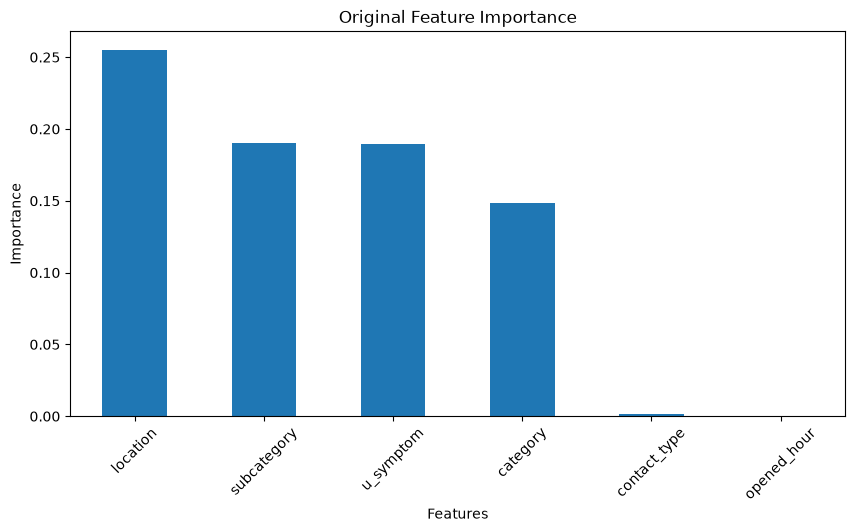

In [343]:
import matplotlib.pyplot as plt

original_feature_importance.plot(
    x="feature",
    y="importance",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Original Feature Importance")
plt.ylabel("Importance")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

## GINI 

In [345]:
important_values=rf_model.feature_importances_

In [346]:
print(important_values)

print(len(important_values))

[7.00181739e-04 2.52071437e-06 1.70465731e-03 7.67587311e-07
 1.18020720e-06 4.90100941e-06 4.40950009e-03 4.49460667e-03
 7.02152990e-06 5.59037096e-03 6.38398311e-06 3.85821405e-04
 1.13778836e-02 4.19647175e-03 9.06375530e-06 7.64878543e-03
 9.76200811e-06 1.58214636e-02 5.22405332e-06 1.08285154e-05
 3.85699795e-05 5.87990562e-03 1.51593505e-05 2.36741810e-03
 2.19578696e-03 6.18995989e-06 5.31864767e-03 3.28506832e-03
 5.89732828e-06 3.56637813e-03 4.61642637e-05 1.03013014e-02
 1.61542240e-03 3.08406112e-03 7.07160115e-03 1.09492067e-02
 2.46386350e-05 1.03667457e-06 2.26548739e-06 1.19009472e-05
 2.58918655e-04 4.85580894e-03 1.11807740e-05 8.55250050e-03
 5.35726189e-05 5.02005564e-03 6.02140619e-05 5.93199352e-03
 4.50444130e-04 3.90432301e-06 4.26876537e-03 1.56151174e-05
 4.01133883e-05 1.34510006e-04 1.69782743e-03 5.08305561e-03
 5.08671358e-04 3.33395029e-04 5.24230364e-06 7.69001768e-04
 3.04377893e-05 1.01057789e-03 3.95901664e-06 5.54739107e-04
 6.41364743e-04 9.587206

In [347]:
feature_names=preprocessor_b.get_feature_names_out()

print("Number of feature names: ",len(feature_names))
print("Number of importance scores:",len(importance_values))

print(feature_names[:10])

Number of feature names:  973
Number of importance scores: 973
['cat__category_?' 'cat__category_Category 10' 'cat__category_Category 13'
 'cat__category_Category 14' 'cat__category_Category 15'
 'cat__category_Category 16' 'cat__category_Category 17'
 'cat__category_Category 19' 'cat__category_Category 2'
 'cat__category_Category 20']


In [348]:
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
})

In [349]:
feature_importance.sort_values(
    by="importance",
    ascending=False
).head(10)


,feature,importance
972,num__opened_hour,0.214303
805,cat__location_Location 143,0.031321
299,cat__u_symptom_?,0.026241
623,cat__u_symptom_Symptom 491,0.023477
861,cat__location_Location 204,0.023060
819,cat__location_Location 161,0.021620
845,cat__location_Location 188,0.019999
125,cat__subcategory_Subcategory 174,0.017869
17,cat__category_Category 28,0.015821
931,cat__location_Location 51,0.015067


In [352]:
feature_importance["original_feature"] = (
    feature_importance["feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
    .str.replace("opened_hour", "opened_hour", regex=False)
    .str.extract(r"^(location|subcategory|u_symptom|category|contact_type|opened_hour)")
)

original_importance = (
    feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
)

display(original_importance)

original_feature
location        0.255296
opened_hour     0.214303
subcategory     0.190351
u_symptom       0.189652
category        0.148612
contact_type    0.001786
Name: importance, dtype: float64

In [353]:
from sklearn.metrics import classification_report,confusion_matrix

print(classification_report(y_test_b,y_pred_rf))

print(confusion_matrix(y_test_b,y_pred_rf))

              precision    recall  f1-score   support

1 - Critical       0.13      0.16      0.15        37
    2 - High       0.22      0.30      0.26        64
3 - Moderate       0.96      0.90      0.93      4734
     4 - Low       0.14      0.40      0.20       148

    accuracy                           0.87      4983
   macro avg       0.36      0.44      0.38      4983
weighted avg       0.92      0.87      0.90      4983

[[   6    2   27    2]
 [   1   19   42    2]
 [  38   62 4269  365]
 [   0    2   87   59]]


In [355]:
from sklearn.pipeline import Pipeline

final_pipeline=Pipeline([
    ("preprocessor",preprocessor_b),
    ("classifier",rf_model)
])

In [356]:
final_pipeline.fit(x_train_b,y_train_b)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['1 - Critical','2 - High','3 - Moderate','4 - Low']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['category','subcategory','contact_type','u_symptom','location', 'opened_hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [357]:
y_pred_final=final_pipeline.predict(x_test_b)

from sklearn.metrics import classification_report

print(classification_report(y_test_b,y_pred_final))

              precision    recall  f1-score   support

1 - Critical       0.13      0.16      0.15        37
    2 - High       0.22      0.30      0.26        64
3 - Moderate       0.96      0.90      0.93      4734
     4 - Low       0.14      0.40      0.20       148

    accuracy                           0.87      4983
   macro avg       0.36      0.44      0.38      4983
weighted avg       0.92      0.87      0.90      4983



In [358]:
import joblib

joblib.dump(final_pipeline,"incident_priority_model.pkl")

['incident_priority_model.pkl']

In [359]:
import pandas as pd
import joblib

loaded_model=joblib.load("incident_priority_model.pkl")
def predict_priority(incident_data):
    new_incident=pd.DataFrame([incident_data])
    prediction=loaded_model.predict(new_incident)
    return prediction[0]

In [360]:
incident = {
    "category": "Category 28",
    "subcategory": "Subcategory 174",
    "contact_type": "Phone",
    "u_symptom": "Symptom 491",
    "location": "Location 143",
    "opened_hour": 10
}

result = predict_priority(incident)

print("Predicted Priority:", result)

Predicted Priority: 3 - Moderate
